# 01 - Data exploration

Goal: understand the 12,330 sessions before we build any model.

Reproduces: paper Section 2.1, Tables 1 and 2.

Needs: nothing. This is the first notebook.

Expected run time: under 1 minute.


## 1. Setup
We load the libraries and set one plot style. We train no model here, so N_REPEATS is not used in this notebook.

In [ ]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # Windows: set before the other imports

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from utils import COLOURS, NUM_COLS, load_data, set_style, show_table

N_REPEATS = 10  # paper uses 100 (not used here)
set_style()

## 2. Load the data
A session is one visit to the website. We check the size of the data, the column types and any missing values. The paper reports 12,330 sessions and no missing values.

In [2]:
df = load_data()
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Fully duplicated rows:", df.duplicated().sum())
print(df.dtypes.to_string())

Shape: (12330, 18)
Missing values: 0
Fully duplicated rows: 125
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                      int64
Revenue                      int64


We get the same size as the paper: 12,330 sessions and 18 columns, which are 17 features plus Revenue. No values are missing. We also found 125 rows that are exact copies of another row. We keep them, because two visitors can behave the same way and the paper does not mention removing any.

## 3. Class balance
The positive class is a session that ends with a purchase. Look at how different the two bars are. The paper reports 84.5% negative and 15.5% positive.

Revenue
0    84.5
1    15.5


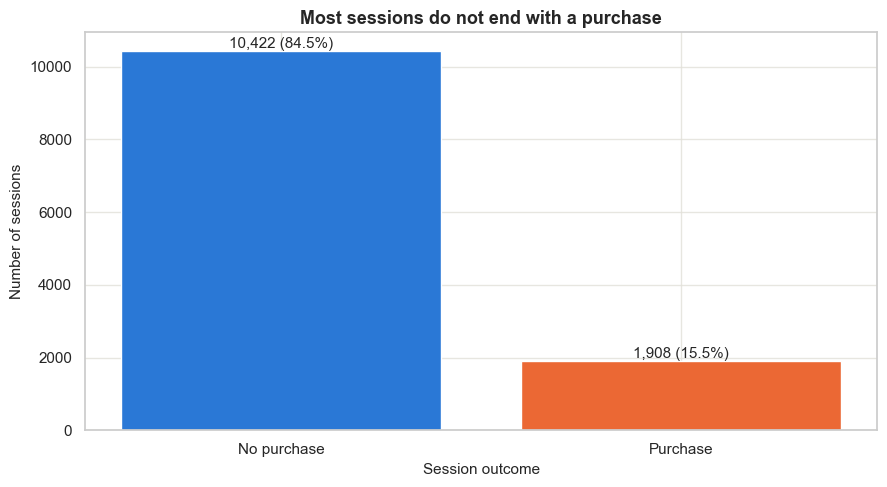

In [3]:
counts = df["Revenue"].value_counts().sort_index()
share = counts / len(df) * 100
print(share.round(1).to_string())

fig, ax = plt.subplots()
bars = ax.bar(["No purchase", "Purchase"], counts.values, color=COLOURS[:2])
ax.bar_label(bars, [f"{c:,} ({s:.1f}%)" for c, s in zip(counts, share)])
ax.set_title("Most sessions do not end with a purchase")
ax.set_xlabel("Session outcome")
ax.set_ylabel("Number of sessions")
plt.tight_layout()
plt.show()

We match the paper exactly: 10,422 sessions (84.5%) have no purchase and 1,908 (15.5%) have one. This matters a lot later. A model that always says "no purchase" is already right 84.5% of the time, so accuracy alone can fool us.

## 4. Table 1: numerical features
This table shows the minimum, maximum and standard deviation of the 10 numerical features, next to the paper's values. Standard deviation tells us how spread out the values are. Compare each of our columns with the paper column beside it.

In [ ]:
# Values copied from paper Table 1, in the order (min, max, SD).
paper_t1 = {
    "Administrative": (0, 27, 3.32), "Administrative_Duration": (0, 3398, 176.70),
    "Informational": (0, 24, 1.26), "Informational_Duration": (0, 2549, 140.64),
    "ProductRelated": (0, 705, 44.45), "ProductRelated_Duration": (0, 63973, 1912.25),
    "BounceRates": (0, 0.2, 0.04), "ExitRates": (0, 0.2, 0.05),
    "PageValues": (0, 361, 18.55), "SpecialDay": (0, 1.0, 0.19),
}

t1 = df[NUM_COLS].agg(["min", "max", "std"]).T
t1.columns = ["Min", "Max", "SD"]
t1["Min (paper)"] = [paper_t1[c][0] for c in t1.index]
t1["Max (paper)"] = [paper_t1[c][1] for c in t1.index]
t1["SD (paper)"] = [paper_t1[c][2] for c in t1.index]
t1 = t1[["Min", "Min (paper)", "Max", "Max (paper)", "SD", "SD (paper)"]]

show_table(t1, "Table 1: numerical features (ours vs paper)", digits=2)

,Min,Min (paper),Max,Max (paper),SD,SD (paper)
Administrative,0.00,0,27.00,27.00,3.32,3.32
Administrative_Duration,0.00,0,3398.75,3398.00,176.78,176.70
Informational,0.00,0,24.00,24.00,1.27,1.26
Informational_Duration,0.00,0,2549.38,2549.00,140.75,140.64
ProductRelated,0.00,0,705.00,705.00,44.48,44.45
ProductRelated_Duration,0.00,0,63973.52,63973.00,1913.67,1912.25
BounceRates,0.00,0,0.20,0.20,0.05,0.04
ExitRates,0.00,0,0.20,0.20,0.05,0.05
PageValues,0.00,0,361.76,361.00,18.57,18.55
SpecialDay,0.00,0,1.00,1.00,0.20,0.19


We are very close to the paper. The minimums all match, and our maximums match once rounded down. Most standard deviations are almost the same, for example 1,913.67 against 1,912.25 for ProductRelated_Duration. The largest gap is BounceRates, which is 0.05 here and 0.04 in the paper. Its real value is about 0.0485. ExitRates has almost the same value (0.0486) and the paper shows it as 0.05, so we do not know why the paper shows 0.04 for BounceRates.

## 5. Table 2: categorical features
This table counts the categories of each categorical feature, next to the paper's count. Look at the Match column.

In [ ]:
paper_t2 = {"OperatingSystems": 8, "Browser": 13, "Region": 9, "TrafficType": 20,
            "VisitorType": 3, "Weekend": 2, "Month": 12, "Revenue": 2}
t2 = pd.DataFrame({"Categories": df[list(paper_t2)].nunique(), "Categories (paper)": pd.Series(paper_t2)})
t2["Match"] = t2["Categories"] == t2["Categories (paper)"]
print("Months in the data:", sorted(df["Month"].unique()))

show_table(t2, "Table 2: categorical features (ours vs paper)", digits=0)

Months in the data: ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']


,Categories,Categories (paper),Match
OperatingSystems,8,8,True
Browser,13,13,True
Region,9,9,True
TrafficType,20,20,True
VisitorType,3,3,True
Weekend,2,2,True
Month,10,12,False
Revenue,2,2,True


All counts match except one. Our data has 10 months, while the paper says 12. January and April do not appear in the file. We do not know why.

## 6. Box plots by outcome
These plots show how four key features differ between buyers and non-buyers. We hide the outliers, because these features have very long tails that would flatten the boxes. Compare the blue and orange box in each plot.

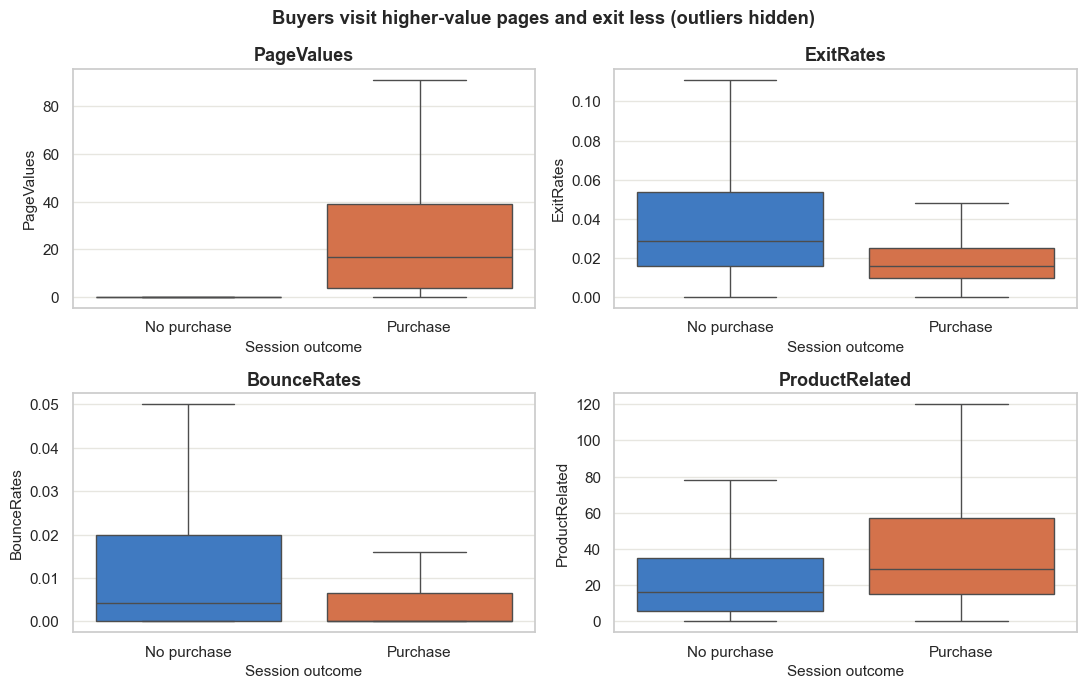

         PageValues  ExitRates  BounceRates  ProductRelated
Revenue                                                    
0             0.000      0.029        0.004            16.0
1            16.758      0.016        0.000            29.0


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ["PageValues", "ExitRates", "BounceRates", "ProductRelated"]):
    sns.boxplot(data=df, x="Revenue", y=col, hue="Revenue", ax=ax, showfliers=False,
                palette=COLOURS[:2], legend=False)
    ax.set_xticks([0, 1], ["No purchase", "Purchase"])
    ax.set_title(col)
    ax.set_xlabel("Session outcome")
    ax.set_ylabel(col)

fig.suptitle("Buyers visit higher-value pages and exit less (outliers are hidden)", fontweight="bold")
plt.tight_layout()
plt.show()

print(df.groupby("Revenue")[["PageValues", "ExitRates", "BounceRates", "ProductRelated"]].median().round(3))

PageValues shows the clearest difference. Its median is 0 for non-buyers and 16.76 for buyers. Buyers also have lower exit rates (median 0.016 against 0.029) and view more product pages (29 against 16). BounceRates is low for both groups, with a median of 0.004 for non-buyers and 0 for buyers.

## 7. Purchase rate by category
Each bar shows the share of sessions that end in a purchase. The dashed line is the overall rate of 15.5%. Look for bars far above or below that line.

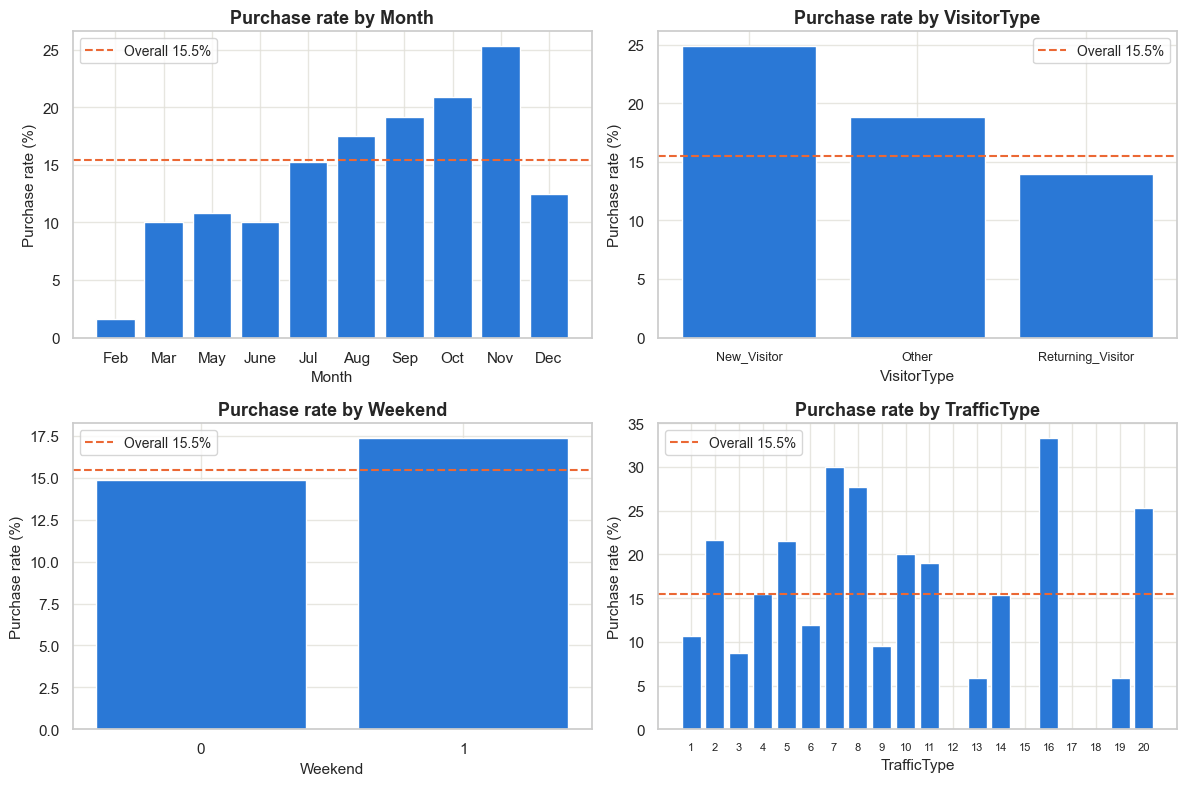

Month
Feb      1.6
June    10.1
Mar     10.1
May     10.9
Dec     12.5
Jul     15.3
Aug     17.6
Sep     19.2
Oct     20.9
Nov     25.4 

VisitorType
Returning_Visitor    13.9
Other                18.8
New_Visitor          24.9 

Weekend
0    14.9
1    17.4 



In [7]:
month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
overall = df["Revenue"].mean() * 100

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["Month", "VisitorType", "Weekend", "TrafficType"]):
    rate = df.groupby(col)["Revenue"].mean() * 100
    if col == "Month":
        rate = rate[month_order]
    ax.bar(rate.index.astype(str), rate.values, color=COLOURS[0])
    ax.axhline(overall, color=COLOURS[1], linestyle="--", label=f"Overall {overall:.1f}%")
    ax.set_title(f"Purchase rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Purchase rate (%)")
    ax.legend()
axes[0, 1].tick_params(axis="x", labelsize=9)
axes[1, 1].tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

for col in ["Month", "VisitorType", "Weekend"]:
    print((df.groupby(col)["Revenue"].mean() * 100).round(1).sort_values().to_string(), "\n")

Timing matters. The purchase rate runs from 1.6% in February to 25.4% in November. New visitors buy more often (24.9%) than returning visitors (13.9%). Weekends are slightly higher than weekdays (17.4% against 14.9%). Traffic types also differ a lot, but we did not check how many sessions some of the small types have, so we do not trust those bars much.

## 8. Correlation of the numerical features
Correlation measures how closely two features move together. The paper notes that BounceRates and ExitRates are highly correlated, so look at that pair in the heatmap.

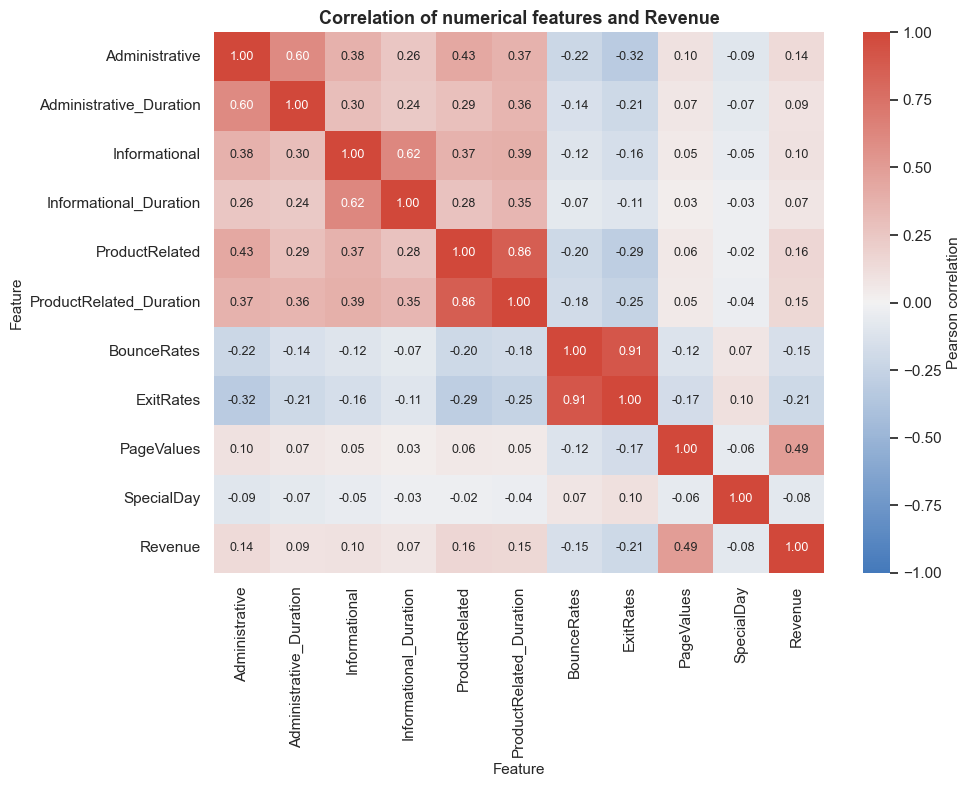

BounceRates vs ExitRates: 0.913
PageValues vs Revenue: 0.493


In [8]:
corr = df[NUM_COLS + ["Revenue"]].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.diverging_palette(250, 15, as_cmap=True),
            vmin=-1, vmax=1, annot_kws={"size": 9}, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation of numerical features and Revenue")
ax.set_xlabel("Feature")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()
print("BounceRates vs ExitRates:", round(corr.loc["BounceRates", "ExitRates"], 3))
print("PageValues vs Revenue:", round(corr.loc["PageValues", "Revenue"], 3))

We confirm what the paper says. BounceRates and ExitRates have a correlation of 0.91, so they carry nearly the same information. This is why the mRMR method ranks BounceRates low in notebook 05. PageValues has the strongest correlation with Revenue, at 0.49.

## 9. Key takeaways
Our data matches the paper in size, class balance and almost all of Tables 1 and 2. There is one real difference: we have 10 months and the paper reports 12. We also found 125 duplicate rows, which we keep.

The classes are very uneven, with only 15.5% of sessions ending in a purchase. PageValues looks like the strongest single signal, with a median of 0 for non-buyers and 16.76 for buyers and a correlation of 0.49 with Revenue. Timing and visitor type also matter: November has 25.4% and February 1.6%, and new visitors buy more often than returning ones (24.9% against 13.9%). BounceRates and ExitRates nearly repeat each other (correlation 0.91).